In [176]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [177]:
df = pd.read_csv('./datasets/netflix_titles.csv')
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [178]:
df.loc[df['rating'] == '84']

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description


In [179]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [180]:
df.shape

(8807, 12)

In [181]:
df.head(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [182]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [183]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(),format ='%B %d, %Y')
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month_name()

In [184]:
df["duration_num"] = df["duration"].str.extract(r"(\d+)").astype(float)
movies = df[df.type == "Movie"].copy()
shows = df[df.type == "TV Show"].copy()

In [185]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
year_added        10
month_added       10
duration_num       3
dtype: int64

In [186]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   str           
 1   type          8807 non-null   str           
 2   title         8807 non-null   str           
 3   director      6173 non-null   str           
 4   cast          7982 non-null   str           
 5   country       7976 non-null   str           
 6   date_added    8797 non-null   datetime64[us]
 7   release_year  8807 non-null   int64         
 8   rating        8803 non-null   str           
 9   duration      8804 non-null   str           
 10  listed_in     8807 non-null   str           
 11  description   8807 non-null   str           
 12  year_added    8797 non-null   float64       
 13  month_added   8797 non-null   str           
 14  duration_num  8804 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(1

In [205]:
df["duration_num"] = pd.to_numeric(
    df["duration_num"], errors="coerce"
)

In [188]:
df.describe()

,date_added,release_year,year_added,duration_num
count,8797,8807.000000,8797.000000,8804.000000
mean,2019-05-17 05:59:08.436967,2014.180198,2018.871888,69.846888
min,2008-01-01 00:00:00,1925.000000,2008.000000,1.000000
25%,2018-04-06 00:00:00,2013.000000,2018.000000,2.000000
50%,2019-07-02 00:00:00,2017.000000,2019.000000,88.000000
75%,2020-08-19 00:00:00,2019.000000,2020.000000,106.000000
max,2021-09-25 00:00:00,2021.000000,2021.000000,312.000000
std,NaN,8.819312,1.574243,50.814828


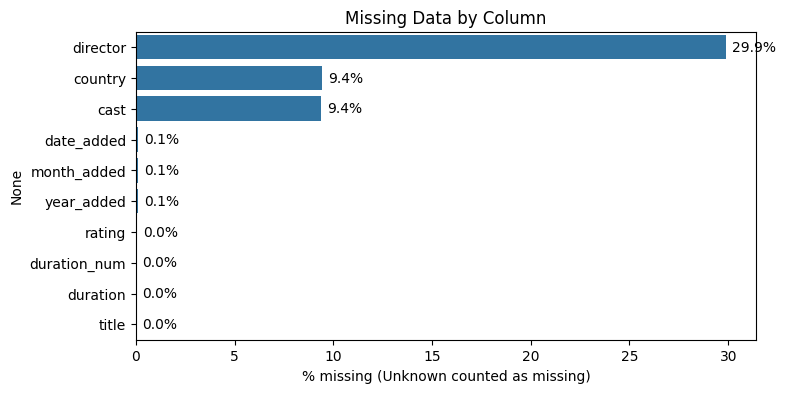

In [189]:
miss = (df.replace("Unknown", np.nan).isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]

plt.figure(figsize=(8, 4))
sns.barplot(x=miss.values, y=miss.index)
plt.xlabel("% missing (Unknown counted as missing)")
plt.title("Missing Data by Column")
for i, v in enumerate(miss.values):
    plt.text(v + 0.3, i, f"{v:.1f}%", va="center")

In [190]:
mask = df["rating"].str.contains("min", na=False)
df.loc[mask, "duration"] = df.loc[mask, "rating"]
df.loc[mask, "rating"] = np.nan


In [191]:
for c in ["director", "cast", "country"]:
    df[c] = df[c].fillna("Unknown")
df["rating"] = df["rating"].fillna("Unknown")
df['date_added']=df['date_added'].fillna("Unknown")
df['year_added'] =df['year_added'].fillna("Unknown")
df['month_added']=df['month_added'].fillna("Unknown")
df['duration_num'] = df['duration_num'].fillna("Unknown")

In [192]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
year_added      0
month_added     0
duration_num    0
dtype: int64

In [193]:
rating_map = {
    "G": "Kids", "TV-G": "Kids", "TV-Y": "Kids", "TV-Y7": "Older Kids",
    "TV-Y7-FV": "Older Kids", "PG": "Older Kids", "TV-PG": "Older Kids",
    "PG-13": "Teens", "TV-14": "Teens",
    "R": "Adults", "TV-MA": "Adults", "NC-17": "Adults",
    "NR": "Unrated", "UR": "Unrated", "Unknown": "Unrated",
}


In [194]:

df["audience"] = df["rating"].map(rating_map)
movies = df[df.type == "Movie"].copy()
shows = df[df.type == "TV Show"].copy()
df["audience"].value_counts()
 

audience
Adults        4009
Teens         2650
Older Kids    1490
Kids           568
Unrated         90
Name: count, dtype: int64

In [195]:
df['director'].value_counts()

director
Unknown                    2634
Rajiv Chilaka                19
Raúl Campos, Jan Suter       18
Suhas Kadav                  16
Marcus Raboy                 16
                           ... 
Mu Chu                        1
Chandra Prakash Dwivedi       1
Majid Al Ansari               1
Peter Hewitt                  1
Mozez Singh                   1
Name: count, Length: 4529, dtype: int64

Text(0.5, 1.0, 'Content Type Split')

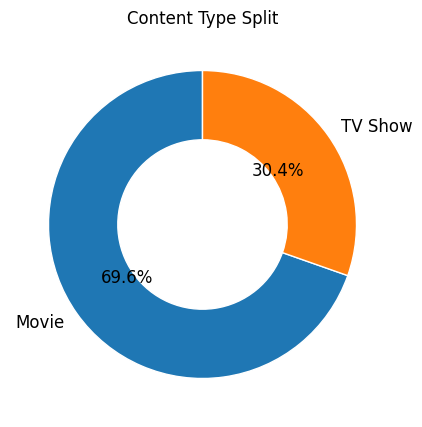

In [196]:
plt.figure(figsize=(5, 5))
counts = df.type.value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
        wedgeprops=dict(width=0.45, edgecolor="white"),
        textprops={"fontsize": 12})
plt.title("Content Type Split")

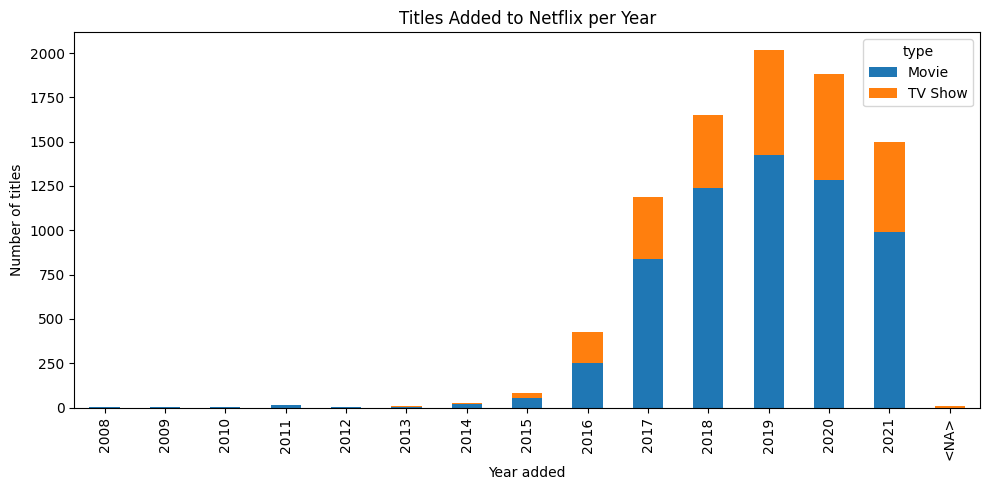

In [197]:
added = df.dropna(subset=["year_added"]).groupby(["year_added", "type"]).size().unstack(fill_value=0)

added.index = pd.to_numeric(added.index, errors='coerce').astype('Int64')

added.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Titles Added to Netflix per Year")
plt.xlabel("Year added"); plt.ylabel("Number of titles")
plt.tight_layout(); plt.show()

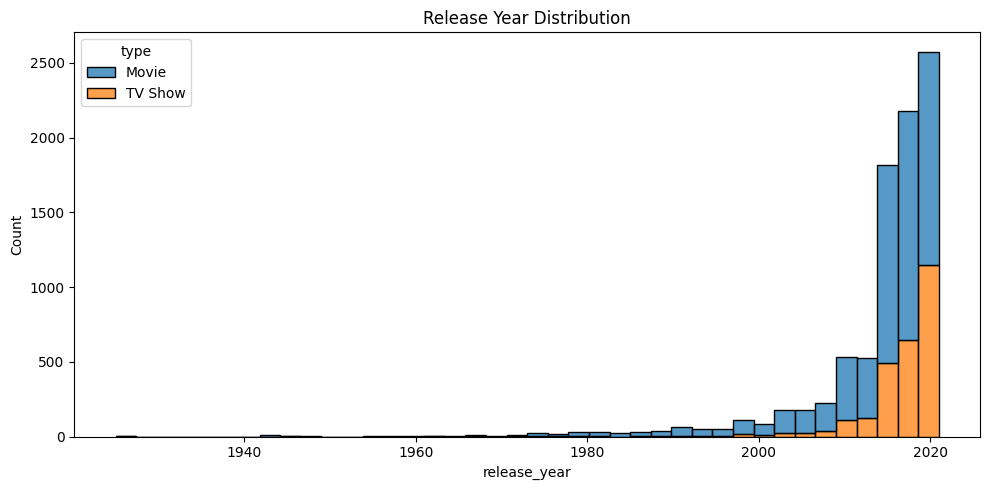

In [198]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="release_year", hue="type", bins=40, multiple="stack",
             )
plt.title("Release Year Distribution")
plt.tight_layout(); plt.show()

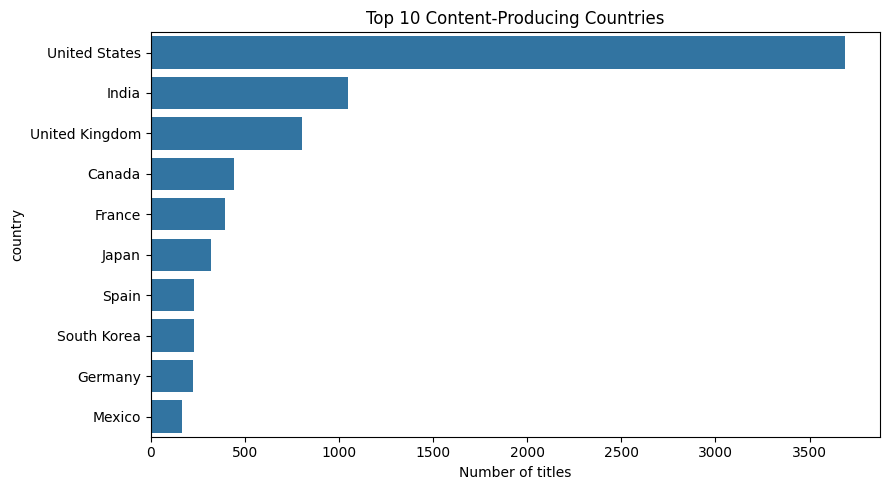

In [199]:
countries = df[df["country"] != "Unknown"]["country"].str.split(",").explode().str.strip()
countries = countries[countries != ""]
top_c = countries.value_counts().head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_c.values, y=top_c.index)
plt.title("Top 10 Content-Producing Countries")
plt.xlabel("Number of titles")
plt.tight_layout(); plt.show()

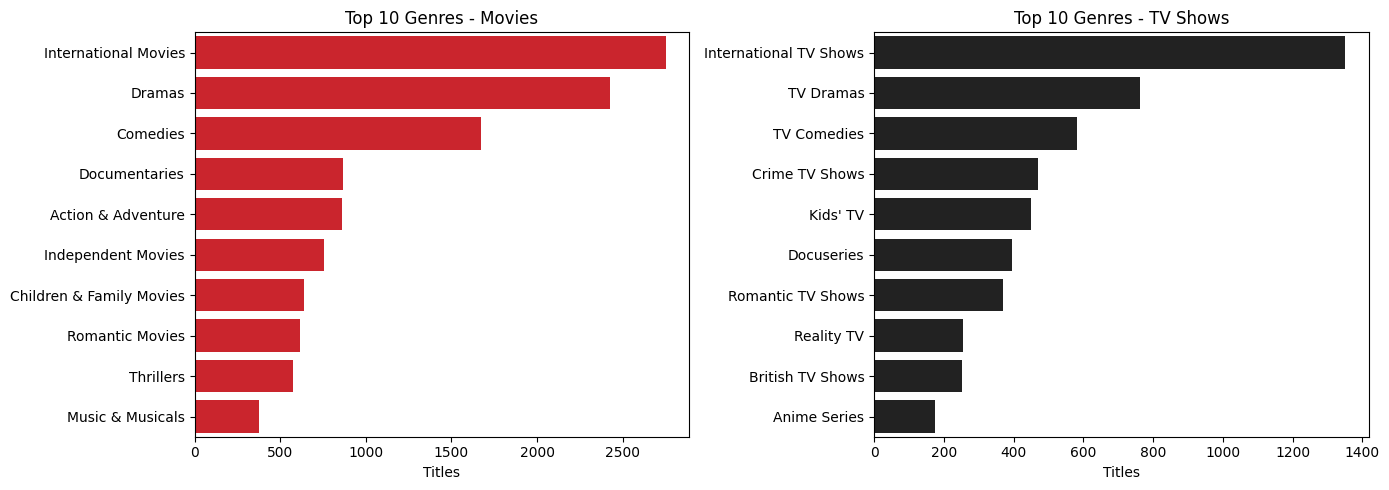

In [200]:
def top_genres(frame, n=10):
    return frame["listed_in"].str.split(",").explode().str.strip().value_counts().head(n)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (name, frame) in zip(ax, [("Movies", movies), ("TV Shows", shows)]):
    g = top_genres(frame)
    sns.barplot(x=g.values, y=g.index, ax=a, color="#E50914" if name == "Movies" else "#222222")
    a.set_title(f"Top 10 Genres - {name}"); a.set_xlabel("Titles"); a.set_ylabel("")
plt.tight_layout(); plt.show()

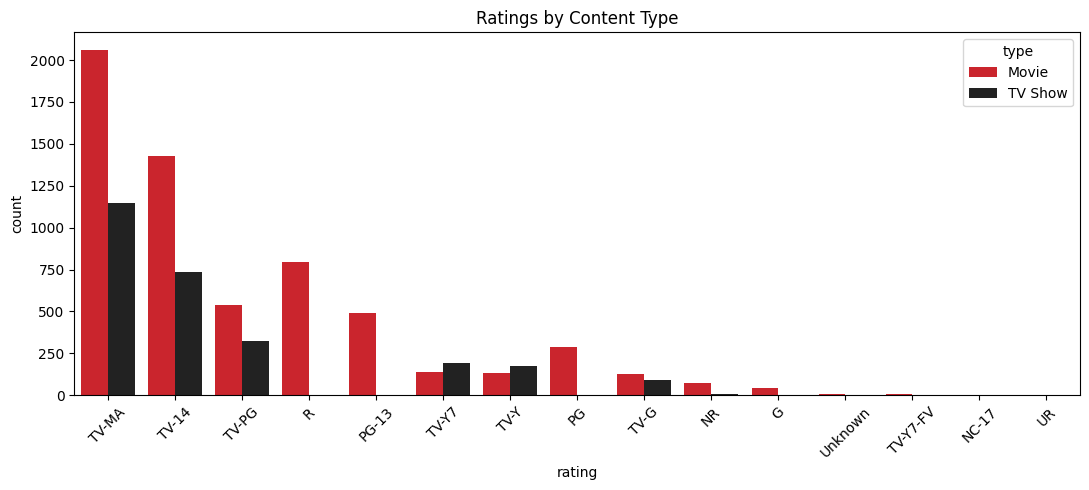

In [201]:
order = df["rating"].value_counts().index

plt.figure(figsize=(11, 5))
sns.countplot(data=df, x="rating", hue="type", order=order, palette=["#E50914", "#222222"])
plt.xticks(rotation=45)
plt.title("Ratings by Content Type")
plt.tight_layout(); plt.show()

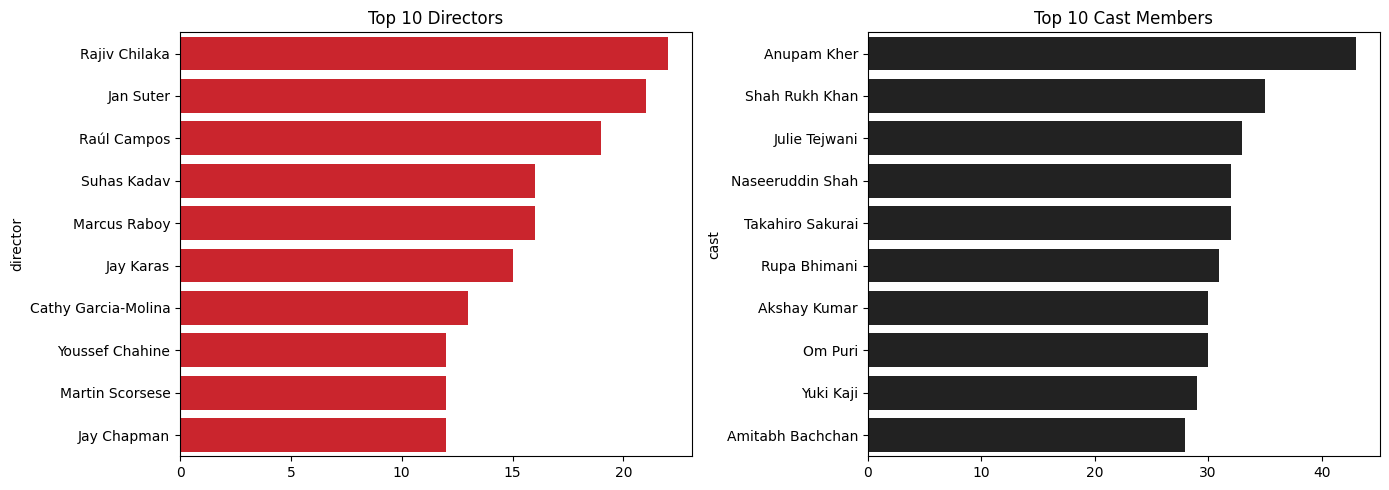

In [202]:
dirs = df[df["director"] != "Unknown"]["director"].str.split(",").explode().str.strip().value_counts().head(10)
cast = df[df["cast"] != "Unknown"]["cast"].str.split(",").explode().str.strip().value_counts().head(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=dirs.values, y=dirs.index, ax=ax[0], color="#E50914"); ax[0].set_title("Top 10 Directors")
sns.barplot(x=cast.values, y=cast.index, ax=ax[1], color='#222222');        ax[1].set_title("Top 10 Cast Members")
plt.tight_layout(); plt.show()

In [203]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   str   
 1   type          8807 non-null   str   
 2   title         8807 non-null   str   
 3   director      8807 non-null   str   
 4   cast          8807 non-null   str   
 5   country       8807 non-null   str   
 6   date_added    8807 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8807 non-null   str   
 9   duration      8807 non-null   str   
 10  listed_in     8807 non-null   str   
 11  description   8807 non-null   str   
 12  year_added    8807 non-null   object
 13  month_added   8807 non-null   str   
 14  duration_num  8807 non-null   object
 15  audience      8807 non-null   str   
dtypes: int64(1), object(3), str(12)
memory usage: 4.1+ MB


In [206]:
print("Movies %%                      : %.1f" % (100 * len(movies) / len(df)))
print("Peak year added                : ", int(df["year_added"].value_counts().idxmax()))
print("Top countries                  : ", top_c.head(3).to_dict())
print("US share of all country tags   : %.1f%%" % (100 * (countries == "United States").sum() / len(countries)))
print("Median movie length (min)      : ", df["duration_num"].median())
print("TV shows with 1 season         : %.1f%%" % (100 * (shows["duration_num"] == 1).mean()))
print("Share TV-MA                    : %.1f%%" % (100 * (df["rating"] == "TV-MA").mean()))
print("Audience split (%)             : ", (df["audience"].value_counts(normalize=True) * 100).round(1).to_dict())
print("Top genres (movies)            : ", top_genres(movies, 3).to_dict())
print("Top genres (shows)             : ", top_genres(shows, 3).to_dict())
print("Top directors                  : ", dirs.head(3).to_dict())
print("Top actors                     : ", cast.head(3).to_dict())
print("Busiest month overall          : ", df["month_added"].value_counts().idxmax())
print("Titles released >= 2015        : %.1f%%" % (100 * (df["release_year"] >= 2015).mean()))
print("Titles added 2019 / 2020 / 2021: ", [int((df["year_added"] == y).sum()) for y in (2019, 2020, 2021)])

Movies %                      : 69.6
Peak year added                :  2019
Top countries                  :  {'United States': 3690, 'India': 1046, 'United Kingdom': 806}
US share of all country tags   : 36.9%
Median movie length (min)      :  88.0
TV shows with 1 season         : 67.0%
Share TV-MA                    : 36.4%
Audience split (%)             :  {'Adults': 45.5, 'Teens': 30.1, 'Older Kids': 16.9, 'Kids': 6.4, 'Unrated': 1.0}
Top genres (movies)            :  {'International Movies': 2752, 'Dramas': 2427, 'Comedies': 1674}
Top genres (shows)             :  {'International TV Shows': 1351, 'TV Dramas': 763, 'TV Comedies': 581}
Top directors                  :  {'Rajiv Chilaka': 22, 'Jan Suter': 21, 'Raúl Campos': 19}
Top actors                     :  {'Anupam Kher': 43, 'Shah Rukh Khan': 35, 'Julie Tejwani': 33}
Busiest month overall          :  July
Titles released >= 2015        : 70.6%
Titles added 2019 / 2020 / 2021:  [2016, 1879, 1498]
